In [ ]:
import os
import random
import shutil

import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import image_dataset_from_directory

In [2]:
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)
print("Training device:", "GPU" if gpus else "CPU")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training device: GPU


# Convolutional Neural Network

In [3]:
def build_model():
    input = keras.Input(shape=(200, 180, 3))
    x = layers.Rescaling(1.0 / 255)(input)
    # 1st-5th ConvLayers
    x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
    x = layers.MaxPool2D(pool_size=2)(x)
    x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
    x = layers.MaxPool2D(pool_size=2)(x)
    x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
    x = layers.MaxPool2D(pool_size=2)(x)
    x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
    x = layers.MaxPool2D(pool_size=2)(x)
    x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
    x = layers.MaxPool2D(pool_size=2)(x)
    x = layers.Flatten()(x)
    output = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs=input, outputs=output)
    return model

In [4]:
model = build_model()
model.summary()

2026-11-14 12:50:34.711558: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-11-14 12:50:34.711591: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-14 12:50:34.711596: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-11-14 12:50:34.711813: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-14 12:50:34.712010: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 200, 180, 3)]     0         
                                                                 
 rescaling (Rescaling)       (None, 200, 180, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 198, 178, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 99, 89, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 97, 87, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 48, 43, 64)        0         
 g2D)                                                        

# Data Processing

In [5]:
shutil.unpack_archive("data_from_kaggle.zip")

source_path = "data_from_kaggle"
output_path = "dataset"
train_ratio = 0.8
random.seed(42)

# create folder
for split in ["train", "validation", "test"]:
    for class_name in ["dog", "cat"]:
        # dataset/train/dog & cat
        folder = os.path.join(output_path, split, class_name)
        os.makedirs(folder, exist_ok=True)

In [6]:
train_source = os.path.join(source_path, "train")
test_source = os.path.join(source_path, "test")
cat_imgs = []
dog_imgs = []
test_cat_imgs = []
test_dog_imgs = []

for filename in os.listdir(train_source):
    if filename.lower().startswith("cat"):
        cat_imgs.append(filename)
    if filename.lower().startswith("dog"):
        dog_imgs.append(filename)

for filename in os.listdir(test_source):
    if filename.lower().startswith("cat"):
        test_cat_imgs.append(filename)
    if filename.lower().startswith("dog"):
        test_dog_imgs.append(filename)

In [7]:
random.shuffle(cat_imgs)
random.shuffle(dog_imgs)

# split 80/20 for train/validation
cat_split = int(len(cat_imgs) * train_ratio)
dog_split = int(len(dog_imgs) * train_ratio)

cat_train = cat_imgs[:cat_split]  # first 8000 images
dog_train = dog_imgs[:dog_split]  # first 7991 images
cat_val = cat_imgs[cat_split:]  # remaining images
dog_val = dog_imgs[dog_split:]  # remaining images

In [8]:
# copy the data from orginal folder to our new folder
for filename in cat_train:
    shutil.copy(
        os.path.join(train_source, filename),
        os.path.join(output_path, "train", "cat", filename),
    )
for filename in dog_train:
    shutil.copy(
        os.path.join(train_source, filename),
        os.path.join(output_path, "train", "dog", filename),
    )

In [9]:
for filename in cat_val:
    shutil.copy(
        os.path.join(train_source, filename),
        os.path.join(output_path, "validation", "cat", filename),
    )
for filename in dog_val:
    shutil.copy(
        os.path.join(train_source, filename),
        os.path.join(output_path, "validation", "dog", filename),
    )

In [10]:
for filename in test_cat_imgs:
    shutil.copy(
        os.path.join(test_source, filename),
        os.path.join(output_path, "test", "cat", filename),
    )
for filename in test_dog_imgs:
    shutil.copy(
        os.path.join(test_source, filename),
        os.path.join(output_path, "test", "dog", filename),
    )

In [11]:
# summary
for split in ["train", "validation", "test"]:
    cat_path = os.path.join("dataset", split, "cat")
    dog_path = os.path.join("dataset", split, "dog")
    num_cat = len(os.listdir(cat_path))
    num_dog = len(os.listdir(dog_path))
    print(f"{split} folder")
    print(f"Dog images: {num_dog}")
    print(f"Cat images: {num_cat}")

train folder
Dog images: 7991
Cat images: 8000
validation folder
Dog images: 1998
Cat images: 2000
test folder
Dog images: 2500
Cat images: 2500


In [12]:
train_dataset = image_dataset_from_directory(
    "dataset/train", image_size=(200, 180), batch_size=32
)
val_dataset = image_dataset_from_directory(
    "dataset/validation", image_size=(200, 180), batch_size=32
)
test_dataset = image_dataset_from_directory(
    "dataset/test", image_size=(200, 180), batch_size=32
)

Found 15991 files belonging to 2 classes.
Found 3998 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


# Training

In [13]:
model.compile(loss="binary_crossentropy", optimizer="rmsprop", metrics=["accuracy"])
history = model.fit(train_dataset, epochs=10, validation_data=val_dataset)

Epoch 1/10


2026-11-14 12:50:41.709334: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


500/500 [==============================] - 23s 39ms/step - loss: 0.6501 - accuracy: 0.6241 - val_loss: 0.5485 - val_accuracy: 0.7156
Epoch 2/10
500/500 [==============================] - 19s 38ms/step - loss: 0.5126 - accuracy: 0.7494 - val_loss: 0.4536 - val_accuracy: 0.7861
Epoch 3/10
500/500 [==============================] - 20s 39ms/step - loss: 0.4235 - accuracy: 0.8105 - val_loss: 0.3985 - val_accuracy: 0.8242
Epoch 4/10
500/500 [==============================] - 20s 40ms/step - loss: 0.3420 - accuracy: 0.8507 - val_loss: 0.3195 - val_accuracy: 0.8532
Epoch 5/10
500/500 [==============================] - 19s 39ms/step - loss: 0.2842 - accuracy: 0.8788 - val_loss: 0.3999 - val_accuracy: 0.8392
Epoch 6/10
500/500 [==============================] - 19s 39ms/step - loss: 0.2270 - accuracy: 0.9063 - val_loss: 0.3151 - val_accuracy: 0.8729
Epoch 7/10
500/500 [==============================] - 20s 40ms/step - loss: 0.1783 - accuracy: 0.9251 - val_loss: 0.3315 - val_accuracy: 0.8829
Epo

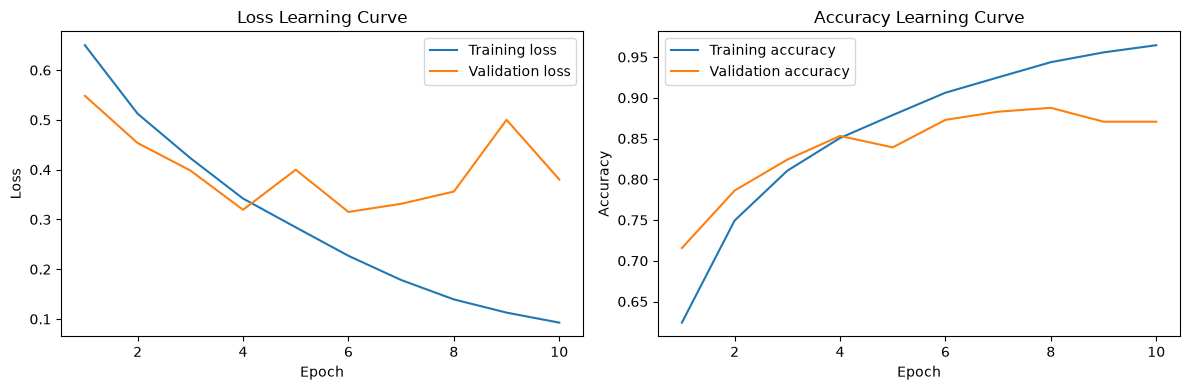

In [14]:
# Learning curves
history = model.history.history
epochs = range(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["loss"], label="Training loss")
axes[0].plot(epochs, history["val_loss"], label="Validation loss")
axes[0].set_title("Loss Learning Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs, history["accuracy"], label="Training accuracy")
axes[1].plot(epochs, history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy Learning Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

# Test

In [15]:
# Test-set performance
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.3847
Test accuracy: 0.8688


1/1 [==============================] - 0s 54ms/step


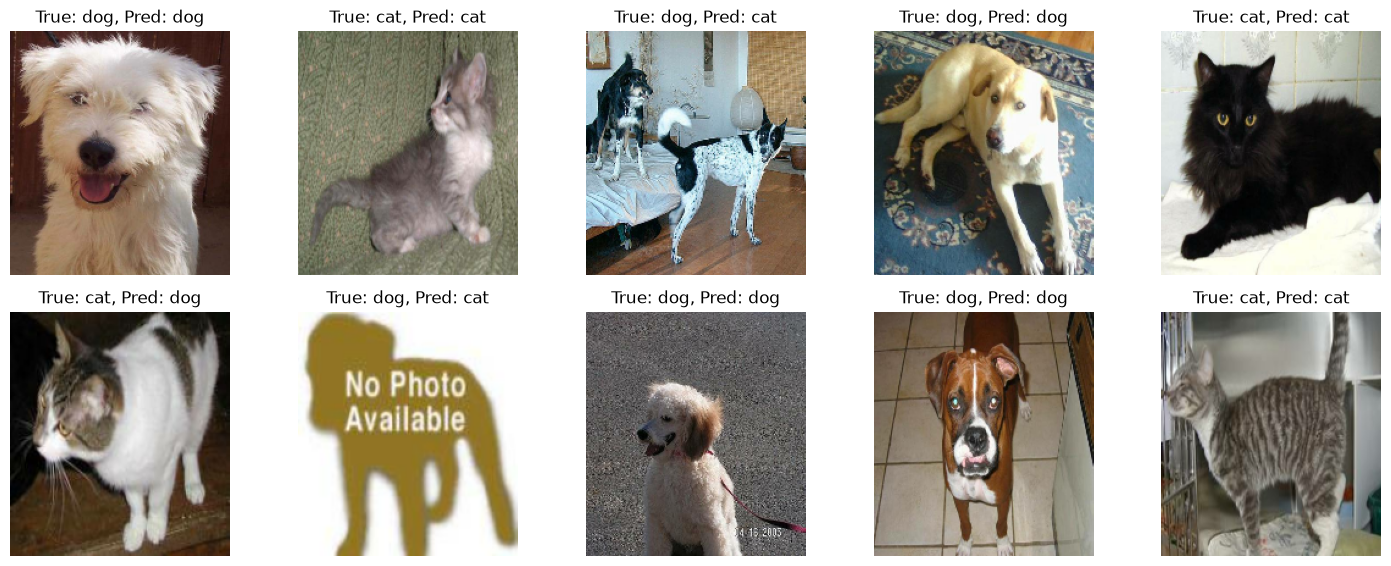

In [16]:
class_name = test_dataset.class_names
for imgs, labels in test_dataset.take(1):
    predictions = model.predict(imgs)
    pred_labels = (predictions > 0.5).astype(int).flatten()
    plt.figure(figsize=(15, 6))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        true_class = class_name[int(labels[i])]
        pred_class = class_name[pred_labels[i]]
        plt.title(f"True: {true_class}, Pred: {pred_class}")
        plt.tight_layout()
        plt.axis("off")